In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_csv("diamonds.CSV.xls")

In [7]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [8]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [9]:
df.shape

(53940, 11)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [11]:
df.describe()

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [12]:
df=df.loc[:,~df.columns.str.contains('Unnamed')]

In [13]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [14]:
df=df.dropna()

In [15]:
df.duplicated().sum()

np.int64(146)

In [16]:
df=df.drop_duplicates()

### data visualization

#### price distributin

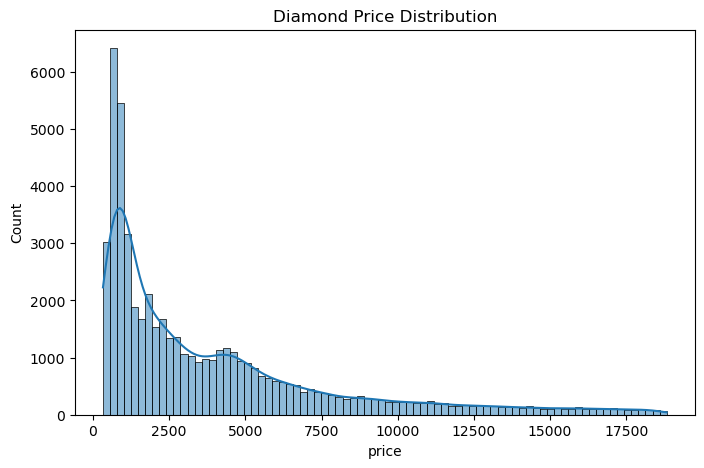

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(df['price'],kde=True)
plt.title("Diamond Price Distribution")
plt.show()

#### carat vs price

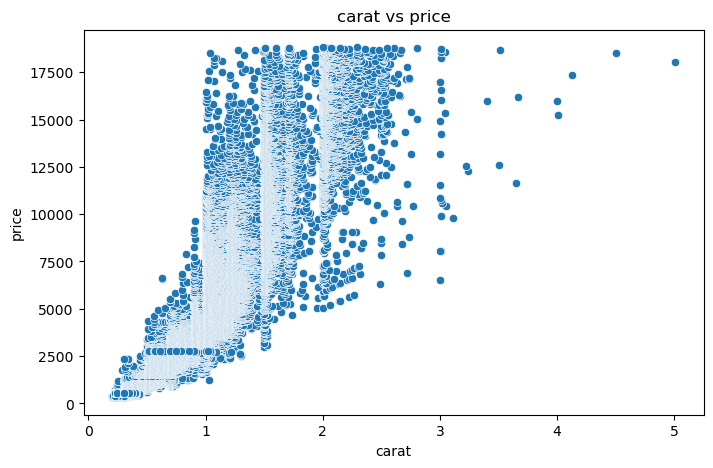

In [18]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='carat',y='price',data=df)
plt.title("carat vs price")
plt.show()

#### cut vs price

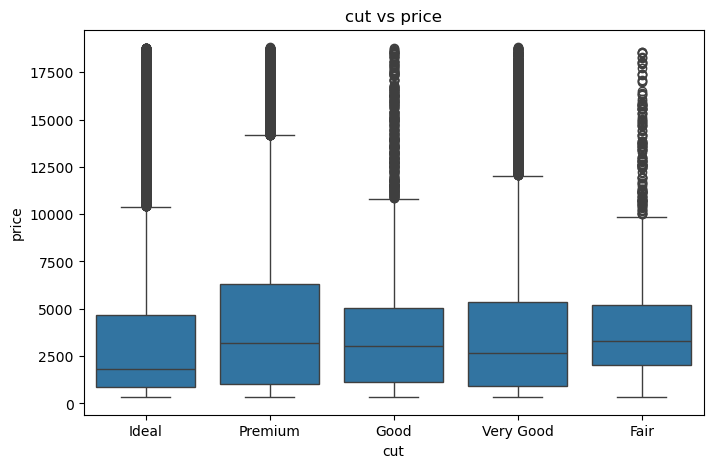

In [19]:
plt.figure(figsize=(8,5))
sns.boxplot(x='cut',y='price',data=df)
plt.title("cut vs price")
plt.show()

In [20]:
df=pd.get_dummies(df,drop_first=True)

In [21]:
x=df.drop("price",axis=1)
y=df["price"]

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [24]:
from sklearn.linear_model import LinearRegression
reg=LinearRegression()

In [25]:
reg.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


#### prediction

In [26]:
y_pred=reg.predict(x_test)

In [27]:
y_pred[:10]

array([ 700.07217051, 3754.66272195, 2630.13669808, 1938.28088804,
       6185.4579702 ,  383.50709289, -671.25646462, 1813.87852012,
       1512.78926398, 5022.6590013 ])

#### model Evaluation

In [28]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [29]:
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

MAE: 725.270321268134
MSE: 1215093.9038325052
R2 Score: 0.9202802581013378


### RMSE

In [30]:
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))

RMSE: 1102.31297907287


#### Actual vs predicted price graph

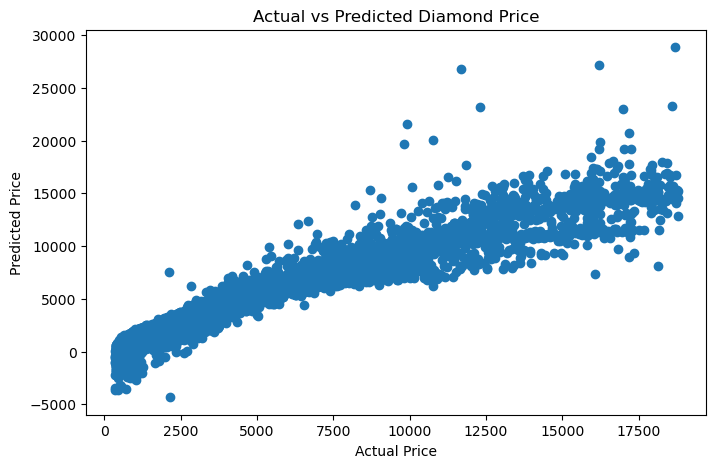

In [31]:
plt.figure(figsize=(8,5))

plt.scatter(y_test,y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Diamond Price")

plt.show()

#### compare actual and predicted price

In [32]:
result = pd.DataFrame({
    "Actual Price":y_test,
    "Predicted Price":y_pred
})

result.head(10)

,Actual Price,Predicted Price
43657,1435,700.072171
4274,3584,3754.662722
47412,1851,2630.136698
44437,1590,1938.280888
13975,5690,6185.457970
11387,596,383.507093
40261,492,-671.256465
49095,2063,1813.878520
37116,970,1512.789264
10485,4796,5022.659001


In [33]:
print("Diamond Price Prediction Project")

print("Algorithm: Linear Regression")

print("R2 Score:",round(r2_score(y_test,y_pred)*100,2),"%")

print("Model Trained Successfully")

Diamond Price Prediction Project
Algorithm: Linear Regression
R2 Score: 92.03 %
Model Trained Successfully


#### predict a new diamond price

In [34]:
new_price = reg.predict(x_test.iloc[[0]])

print("Predicted Diamond Price:",new_price[0])

Predicted Diamond Price: 700.0721705147216
